# 03 - Zones: boundaries, centroids, ZIP crosswalk
**Input:** `data/raw/modzcta_boundaries.geojson`, `data/raw/community_district_boundaries.geojson`
**Output:** `data/interim/zones_modzcta.csv`, `data/interim/zip_to_modzcta.csv`, `data/interim/zones_cd.csv`

The EMS data only gives ZIP / community district / precinct, so the spatial unit is a **zone** and travel times
use **zone centroids**. Default zone = MODZCTA (NYC's modified ZIP areas; merges tiny ZIPs). Community district
is the fallback if ZIP coverage is poor (checked in notebook 07).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "README.md").exists())
sys.path.insert(0, str(ROOT / "src"))
RAW, INTERIM, PROCESSED = ROOT / "data/raw", ROOT / "data/interim", ROOT / "data/processed"
NB_DATA = ROOT / "notebooks/data"
INTERIM.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)

In [2]:
from grease.data.geo import load_geojson, feature_centroid

mod = load_geojson(RAW / "modzcta_boundaries.geojson")
zones = pd.DataFrame([{**f["props"], "lon": (c := feature_centroid(f["polys"]))[0], "lat": c[1]} for f in mod])
zones["pop_est"] = pd.to_numeric(zones.pop_est, errors="coerce")
zones = zones.rename(columns={"modzcta": "zone"})
print(len(zones), "MODZCTA zones; centroid bbox:", zones.lon.min().round(3), zones.lon.max().round(3), zones.lat.min().round(3), zones.lat.max().round(3))
zones.head()

178 MODZCTA zones; centroid bbox: -74.239 -73.711 40.508 40.9


,zone,label,zcta,pop_est,lon,lat
0,10001,"10001, 10118","10001, 10119, 10199",23072,-73.997138,40.750688
1,10002,10002,10002,74993,-73.986174,40.715780
2,10003,10003,10003,54682,-73.989159,40.731826
3,10026,10026,10026,39363,-73.952672,40.802382
4,10004,10004,10004,3028,-74.013033,40.703747


In [3]:
# ZIP -> MODZCTA crosswalk: a MODZCTA's `zcta` field lists every ZCTA merged into it, `label` lists the ZIPs
rows = []
for _, r in zones.iterrows():
    for z in {z.strip() for z in f"{r.label},{r.zcta},{r.zone}".split(",")}:
        rows.append({"zipcode": z, "zone": r.zone})
xw = pd.DataFrame(rows).drop_duplicates("zipcode")
print(len(xw), "ZIPs map to", xw.zone.nunique(), "zones")
dups = pd.DataFrame(rows).groupby("zipcode").zone.nunique(); print("ZIPs in >1 zone:", int((dups > 1).sum()))

219 ZIPs map to 178 zones
ZIPs in >1 zone: 0


In [4]:
BORO = {"1": "MANHATTAN", "2": "BRONX", "3": "BROOKLYN", "4": "QUEENS", "5": "STATEN ISLAND"}
cd = load_geojson(RAW / "community_district_boundaries.geojson")
cdz = pd.DataFrame([{"communitydistrict": int(f["props"]["boro_cd"]), "lon": (c := feature_centroid(f["polys"]))[0], "lat": c[1]} for f in cd])
cdz["borough"] = cdz.communitydistrict.astype(str).str[0].map(BORO)
# keep real residential CDs (parks / airports have codes like 164, 226, 227, 228, 355, 356, 480, 481, 482, 483, 484, 595)
cdz["is_park_or_other"] = cdz.communitydistrict % 100 > 18
print(len(cdz), "CD polygons;", int(cdz.is_park_or_other.sum()), "are parks/airports/other")

zones.to_csv(INTERIM / "zones_modzcta.csv", index=False)
xw.to_csv(INTERIM / "zip_to_modzcta.csv", index=False)
cdz.to_csv(INTERIM / "zones_cd.csv", index=False)

71 CD polygons; 12 are parks/airports/other


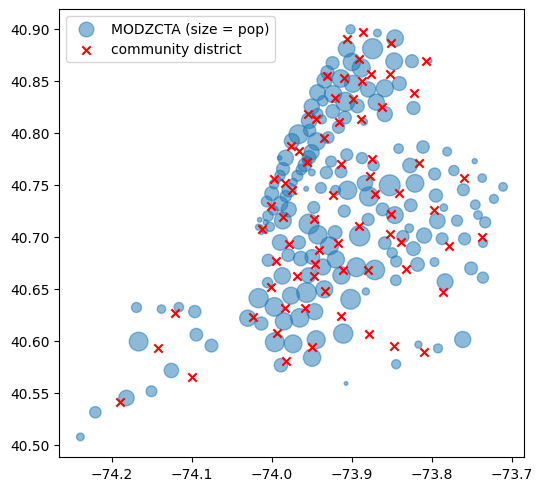

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(zones.lon, zones.lat, s=zones.pop_est.fillna(1000) / 500, alpha=.5, label="MODZCTA (size = pop)")
ax.scatter(cdz.lon, cdz.lat, marker="x", c="r", label="community district"); ax.legend(); ax.set_aspect(1.3); plt.show()